
# Audio Preprocessing and Voiceprint Verification

## 1. Introduction

This notebook focuses on the preprocessing and analysis of audio recordings for the multimodal authentication system.

The main objective is to develop a voiceprint verification component that can verify whether a spoken recording belongs to an enrolled team member.

Each of the three team members contributes two original audio recordings:
- "Yes, approve"
- "Confirm transaction"

The notebook covers audio loading, visualisation, preprocessing, augmentation, feature extraction, and voiceprint verification.

The extracted audio features and verification component will later be integrated into the final multimodal system.


## 2. Environment Setup

In this section, we import the Python libraries required for audio processing, visualisation, feature extraction, and model development.

We will also connect Google Drive to access the audio recordings and save the processed outputs.


In [2]:
!pip install librosa soundfile scikit-learn matplotlib pandas numpy -q

In [3]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Formative-2-Multimodal-System"
)

RAW_AUDIO_DIR = PROJECT_DIR / "data" / "raw" / "audio"

PROCESSED_AUDIO_DIR = PROJECT_DIR / "data" / "processed" / "audio"

AUGMENTED_AUDIO_DIR = PROJECT_DIR / "data" / "processed" / "audio_augmented"

OUTPUT_DIR = PROJECT_DIR / "outputs" / "audio"

# Create output folders if they do not already exist
PROCESSED_AUDIO_DIR.mkdir(parents=True, exist_ok=True)
AUGMENTED_AUDIO_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folders configured successfully!")
print("Raw audio folder:", RAW_AUDIO_DIR)

Project folders configured successfully!
Raw audio folder: /content/drive/MyDrive/Formative-2-Multimodal-System/data/raw/audio


In [6]:
for member_folder in sorted(RAW_AUDIO_DIR.iterdir()):
    if member_folder.is_dir():
        audio_files = list(member_folder.glob("*.wav"))

        print(f"\n{member_folder.name}: {len(audio_files)} recordings")

        for audio_file in sorted(audio_files):
            print("  -", audio_file.name)


member_1: 2 recordings
  - kellia_confirm_transaction.wav
  - kellia_yes_approve.wav

member_2: 2 recordings
  - Mildred_confirm_transaction.wav
  - Mildred_yes_approve.wav

member_3: 2 recordings
  - Auriane_confirm_transaction.wav
  - Auriane_yes_approve.wav



## 3. Loading Audio Data

In this section, we load the original audio recordings from the project directory.

The recordings are organised into separate folders for each team member. We will load each WAV file and store its audio signal, sample rate, member ID, and filename.

This will allow us to inspect and process all recordings consistently in the following sections.


In [7]:
# Store all loaded audio recordings
audio_records = []

# Loop through each member's folder
for member_folder in sorted(RAW_AUDIO_DIR.iterdir()):

    if not member_folder.is_dir():
        continue

    member_id = member_folder.name

    # Find WAV files
    audio_files = sorted(member_folder.glob("*.wav"))

    for audio_file in audio_files:

        # Load audio without changing its original sample rate
        audio, sample_rate = sf.read(audio_file, always_2d=True)

        # Calculate duration
        duration = len(audio) / sample_rate

        # Store recording information
        audio_records.append({
            "member_id": member_id,
            "filename": audio_file.name,
            "file_path": str(audio_file),
            "audio": audio,
            "sample_rate": sample_rate,
            "channels": audio.shape[1],
            "duration_seconds": duration
        })

print(f"Successfully loaded {len(audio_records)} recordings.")


Successfully loaded 6 recordings.


In [8]:
audio_summary = pd.DataFrame([
    {
        "Member": record["member_id"],
        "Filename": record["filename"],
        "Sample Rate (Hz)": record["sample_rate"],
        "Channels": record["channels"],
        "Duration (seconds)": round(record["duration_seconds"], 2)
    }
    for record in audio_records
])

display(audio_summary)


,Member,Filename,Sample Rate (Hz),Channels,Duration (seconds)
0,member_1,kellia_confirm_transaction.wav,44100,1,2.35
1,member_1,kellia_yes_approve.wav,44100,1,2.87
2,member_2,Mildred_confirm_transaction.wav,48000,2,3.71
3,member_2,Mildred_yes_approve.wav,48000,2,3.39
4,member_3,Auriane_confirm_transaction.wav,48000,2,2.22
5,member_3,Auriane_yes_approve.wav,48000,2,2.05


In [9]:
print("TOTAL RECORDINGS:", len(audio_records))

print("\nSAMPLE RATE DISTRIBUTION:")
print(audio_summary["Sample Rate (Hz)"].value_counts())

print("\nCHANNEL DISTRIBUTION:")
print(audio_summary["Channels"].value_counts())

print("\nDURATION SUMMARY:")
print(audio_summary["Duration (seconds)"].describe())

# Check for missing or unreadable recordings
if len(audio_records) == 6:
    print("\nAll six expected recordings were loaded.")
else:
    print("\nWARNING: We expected six recordings. Please check the folders.")

if (audio_summary["Duration (seconds)"] <= 0).any():
    print("WARNING: At least one recording has an invalid duration.")
else:
    print("All recordings have valid durations.")


TOTAL RECORDINGS: 6

SAMPLE RATE DISTRIBUTION:
Sample Rate (Hz)
48000    4
44100    2
Name: count, dtype: int64

CHANNEL DISTRIBUTION:
Channels
2    4
1    2
Name: count, dtype: int64

DURATION SUMMARY:
count    6.000000
mean     2.765000
std      0.674559
min      2.050000
25%      2.252500
50%      2.610000
75%      3.260000
max      3.710000
Name: Duration (seconds), dtype: float64

All six expected recordings were loaded.
All recordings have valid durations.



## 4. Audio Exploration and Visualisation

Audio visualisation helps us understand the characteristics of the collected recordings.

We will use waveforms to examine the amplitude of each audio signal over time and spectrograms to observe how different frequencies are distributed throughout the recordings.

These visualisations will help identify silence, recording inconsistencies, and differences between samples.


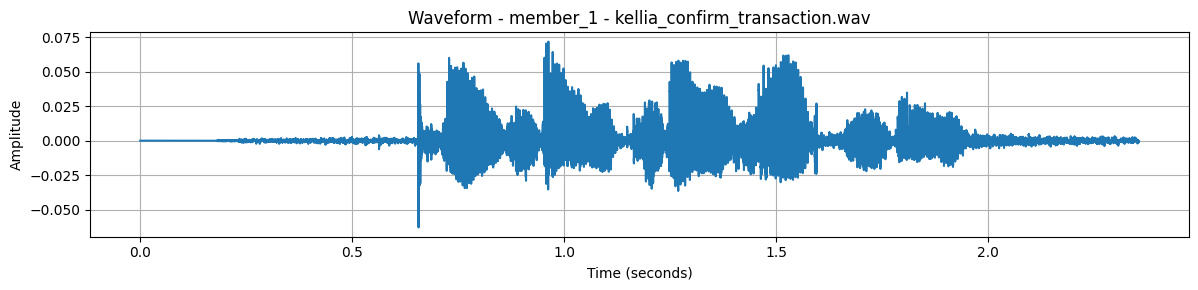

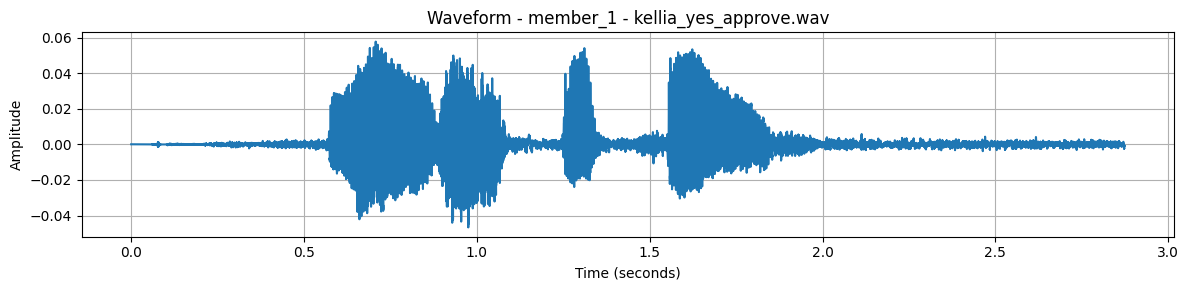

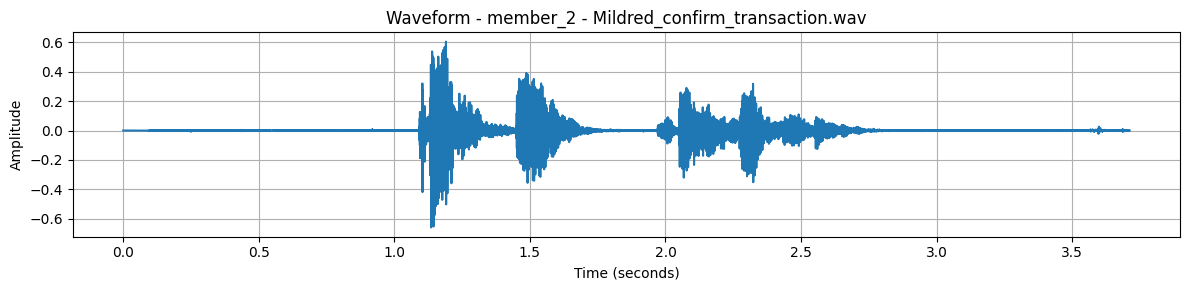

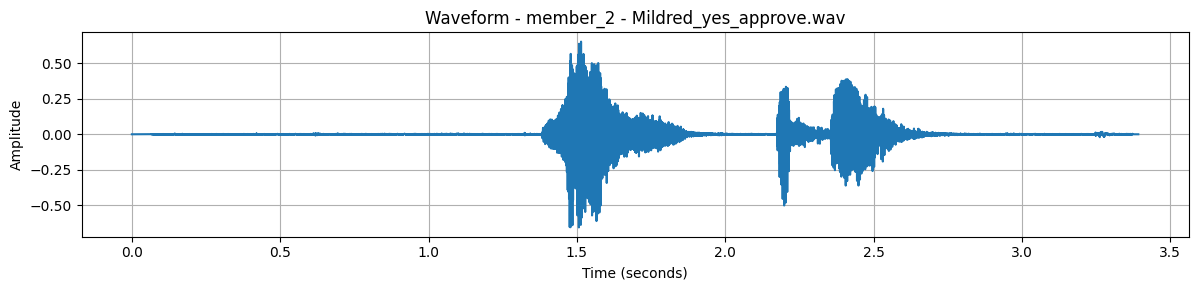

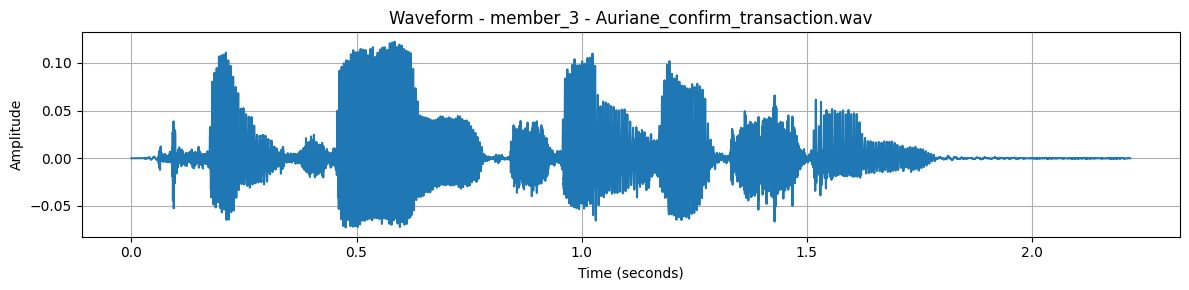

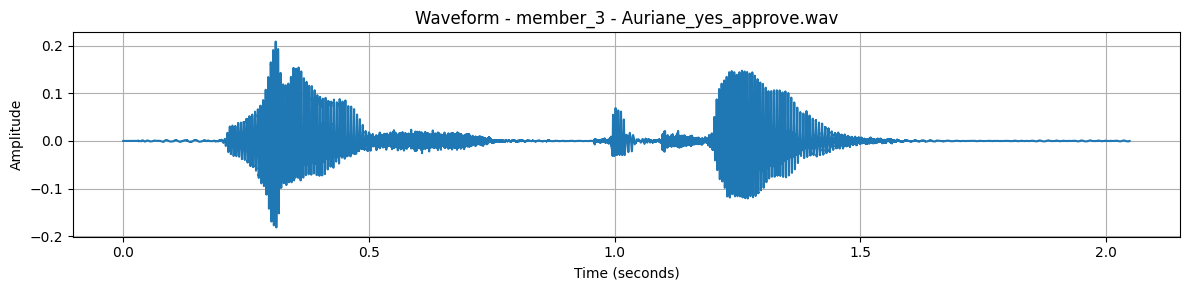

In [10]:
def plot_waveform(audio, sample_rate, title):

    # Convert to mono for visualisation
    mono_audio = np.mean(audio, axis=1)

    # Generate time values
    time = np.arange(len(mono_audio)) / sample_rate

    plt.figure(figsize=(12, 3))
    plt.plot(time, mono_audio)
    plt.title(title)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


for record in audio_records:

    plot_waveform(
        record["audio"],
        record["sample_rate"],
        f'Waveform - {record["member_id"]} - {record["filename"]}'
    )


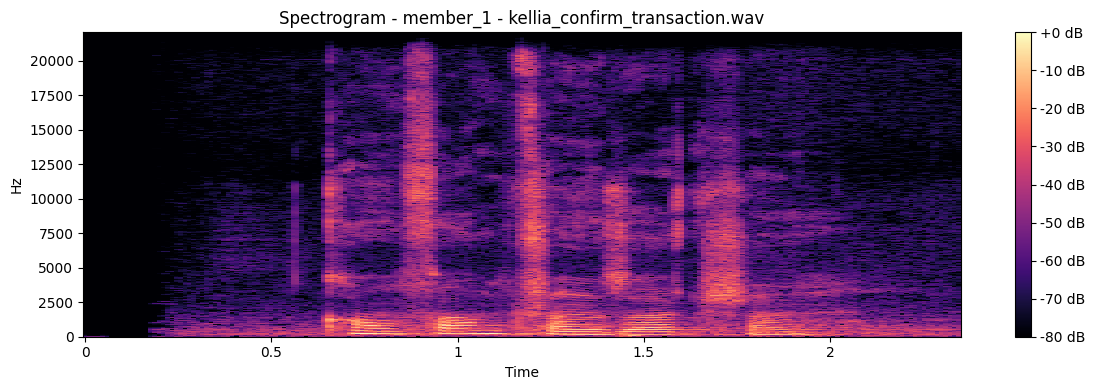

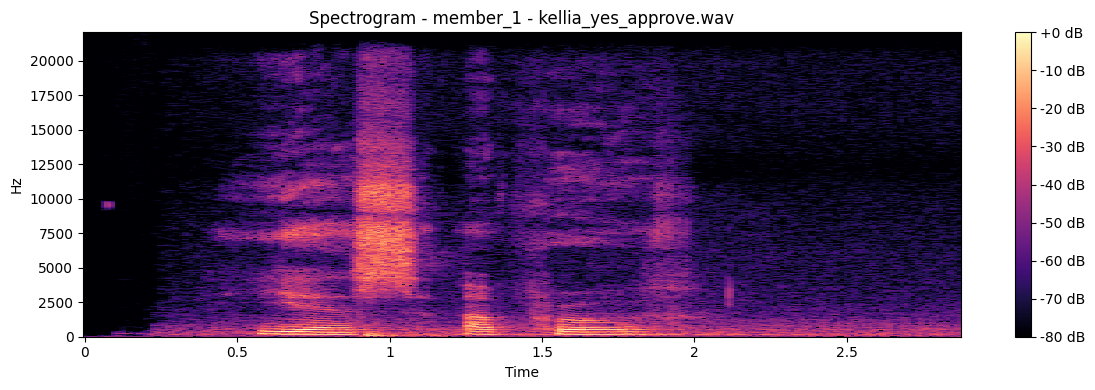

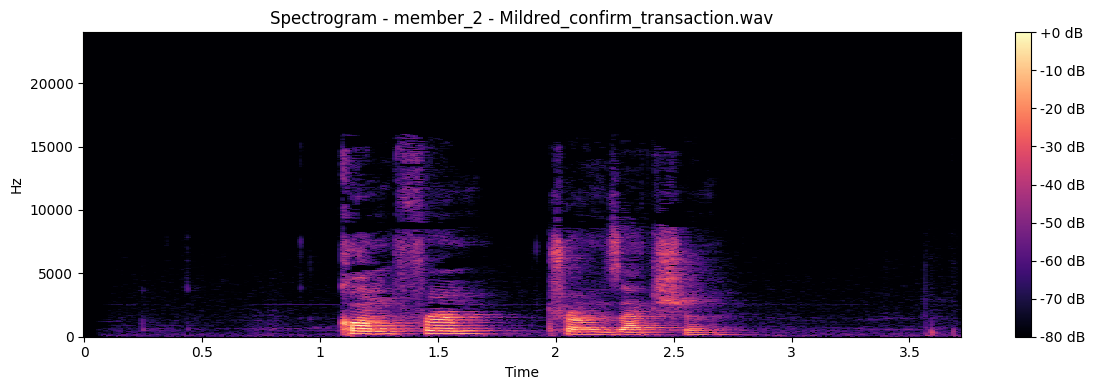

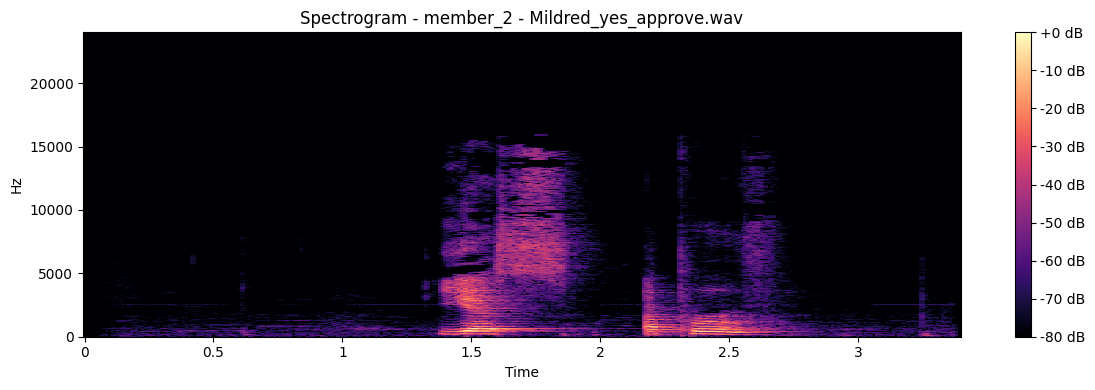

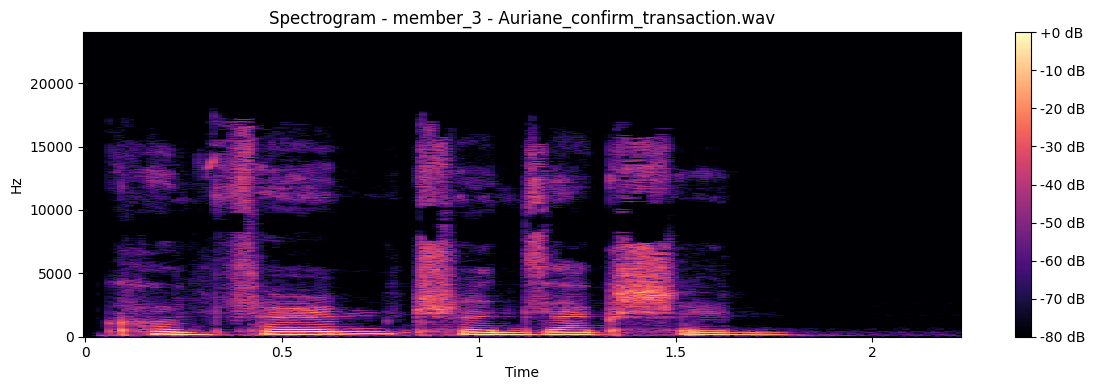

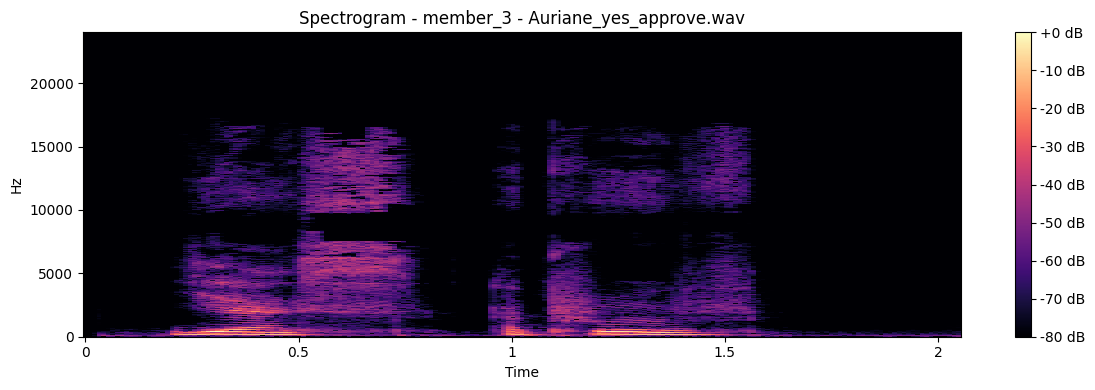

In [11]:

def plot_spectrogram(audio, sample_rate, title):

    # Convert to mono
    mono_audio = np.mean(audio, axis=1)

    # Calculate Short-Time Fourier Transform
    D = librosa.stft(mono_audio)

    # Convert amplitude to decibels
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    plt.figure(figsize=(12, 4))

    librosa.display.specshow(
        S_db,
        sr=sample_rate,
        x_axis="time",
        y_axis="hz"
    )

    plt.colorbar(format="%+2.0f dB")
    plt.title(title)
    plt.tight_layout()
    plt.show()


for record in audio_records:

    plot_spectrogram(
        record["audio"],
        record["sample_rate"],
        f'Spectrogram - {record["member_id"]} - {record["filename"]}'
    )



## 5. Audio Preprocessing

The original recordings have different sample rates and channel configurations. To ensure consistency, we will standardise all recordings before feature extraction.

The preprocessing steps include:

1. Converting stereo recordings into mono.
2. Resampling all recordings to 16,000 Hz.
3. Trimming unnecessary silence at the beginning and end of recordings.
4. Normalising the audio amplitude to a consistent peak level.
5. Saving the processed recordings as 16-bit PCM WAV files.

The original recordings will remain unchanged, while the processed versions will be stored separately.


In [12]:
# Standard audio configuration
TARGET_SAMPLE_RATE = 16000
TARGET_CHANNELS = 1
TARGET_PEAK = 0.95

# Create separate folders for each member
for member in ["member_1", "member_2", "member_3"]:
    (PROCESSED_AUDIO_DIR / member).mkdir(parents=True, exist_ok=True)

print("Audio preprocessing settings configured.")
print("Target sample rate:", TARGET_SAMPLE_RATE, "Hz")
print("Target channels:", TARGET_CHANNELS)


Audio preprocessing settings configured.
Target sample rate: 16000 Hz
Target channels: 1


In [14]:

processed_records = []

for record in audio_records:

    audio = record["audio"]
    original_sr = record["sample_rate"]

    # Step 1: Convert stereo to mono
    mono_audio = np.mean(audio, axis=1)

    # Step 2: Resample to 16,000 Hz
    resampled_audio = librosa.resample(
        mono_audio,
        orig_sr=original_sr,
        target_sr=TARGET_SAMPLE_RATE
    )

    # Step 3: Trim leading and trailing silence
    trimmed_audio, trim_indices = librosa.effects.trim(
        resampled_audio,
        top_db=30
    )

    # Step 4: Normalise peak amplitude
    peak = np.max(np.abs(trimmed_audio))

    if peak > 0:
        normalised_audio = (trimmed_audio / peak) * TARGET_PEAK
    else:
        normalised_audio = trimmed_audio

    # Step 5: Save processed audio
    output_path = (
        PROCESSED_AUDIO_DIR
        / record["member_id"]
        / record["filename"]
    )

    sf.write(
        output_path,
        normalised_audio,
        TARGET_SAMPLE_RATE,
        subtype="PCM_16"
    )

    # Store processed recording information
    processed_records.append({
        "member_id": record["member_id"],
        "filename": record["filename"],
        "audio": normalised_audio,
        "sample_rate": TARGET_SAMPLE_RATE,
        "duration_seconds": len(normalised_audio) / TARGET_SAMPLE_RATE,
        "file_path": str(output_path)
    })

print(f"Successfully processed {len(processed_records)} recordings.")

Successfully processed 6 recordings.


In [15]:

processed_summary = pd.DataFrame([
    {
        "Member": record["member_id"],
        "Filename": record["filename"],
        "Sample Rate (Hz)": record["sample_rate"],
        "Channels": 1,
        "Duration (seconds)": round(record["duration_seconds"], 2)
    }
    for record in processed_records
])

display(processed_summary)

# Verify the saved WAV files
for record in processed_records:

    saved_audio, saved_sr = sf.read(record["file_path"])

    print(
        record["filename"],
        "| Sample rate:", saved_sr,
        "| Shape:", saved_audio.shape
    )

,Member,Filename,Sample Rate (Hz),Channels,Duration (seconds)
0,member_1,kellia_confirm_transaction.wav,16000,1,2.07
1,member_1,kellia_yes_approve.wav,16000,1,2.46
2,member_2,Mildred_confirm_transaction.wav,16000,1,1.73
3,member_2,Mildred_yes_approve.wav,16000,1,1.34
4,member_3,Auriane_confirm_transaction.wav,16000,1,1.82
5,member_3,Auriane_yes_approve.wav,16000,1,1.41


kellia_confirm_transaction.wav | Sample rate: 16000 | Shape: (33067,)
kellia_yes_approve.wav | Sample rate: 16000 | Shape: (39320,)
Mildred_confirm_transaction.wav | Sample rate: 16000 | Shape: (27648,)
Mildred_yes_approve.wav | Sample rate: 16000 | Shape: (21504,)
Auriane_confirm_transaction.wav | Sample rate: 16000 | Shape: (29184,)
Auriane_yes_approve.wav | Sample rate: 16000 | Shape: (22528,)


In [16]:

comparison = pd.DataFrame([
    {
        "Member": original["member_id"],
        "Filename": original["filename"],
        "Original Duration": round(original["duration_seconds"], 2),
        "Processed Duration": round(processed["duration_seconds"], 2),
        "Original Sample Rate": original["sample_rate"],
        "Processed Sample Rate": processed["sample_rate"]
    }
    for original, processed in zip(audio_records, processed_records)
])

display(comparison)

,Member,Filename,Original Duration,Processed Duration,Original Sample Rate,Processed Sample Rate
0,member_1,kellia_confirm_transaction.wav,2.35,2.07,44100,16000
1,member_1,kellia_yes_approve.wav,2.87,2.46,44100,16000
2,member_2,Mildred_confirm_transaction.wav,3.71,1.73,48000,16000
3,member_2,Mildred_yes_approve.wav,3.39,1.34,48000,16000
4,member_3,Auriane_confirm_transaction.wav,2.22,1.82,48000,16000
5,member_3,Auriane_yes_approve.wav,2.05,1.41,48000,16000



## 6. Listening to Processed Audio

Before applying augmentation, we listen to the processed recordings to verify that the speech remains clear and complete after trimming and normalisation.

This quality check helps identify recordings where important speech may have been removed during preprocessing.


In [17]:

from IPython.display import Audio, display

for record in processed_records:

    print(
        f'{record["member_id"]} - {record["filename"]}'
    )

    display(
        Audio(
            record["audio"],
            rate=record["sample_rate"]
        )
    )

member_1 - kellia_confirm_transaction.wav


member_1 - kellia_yes_approve.wav


member_2 - Mildred_confirm_transaction.wav


member_2 - Mildred_yes_approve.wav


member_3 - Auriane_confirm_transaction.wav


member_3 - Auriane_yes_approve.wav



## 7. Audio Augmentation

Audio augmentation increases the diversity of the training data by creating modified versions of the original recordings.

In this notebook, we apply two augmentation techniques:

1. Pitch shifting to introduce small variations in voice pitch.
2. Background noise addition to simulate different recording environments.

Each original recording produces two augmented samples. The original recordings are preserved, and the augmented versions are saved separately.

These variations help us explore how voice features behave under slightly different audio conditions.


In [18]:

# Augmentation settings
PITCH_SHIFT_STEPS = 1
TARGET_SNR_DB = 25

# Make results reproducible
np.random.seed(42)

# Create augmentation folders
for member in ["member_1", "member_2", "member_3"]:
    (AUGMENTED_AUDIO_DIR / member).mkdir(parents=True, exist_ok=True)

print("Augmentation settings configured successfully.")

Augmentation settings configured successfully.


In [19]:

pitch_augmented_records = []

for record in processed_records:

    augmented_audio = librosa.effects.pitch_shift(
        y=record["audio"],
        sr=TARGET_SAMPLE_RATE,
        n_steps=PITCH_SHIFT_STEPS
    )

    filename = Path(record["filename"]).stem + "_pitch.wav"

    output_path = (
        AUGMENTED_AUDIO_DIR
        / record["member_id"]
        / filename
    )

    sf.write(
        output_path,
        augmented_audio,
        TARGET_SAMPLE_RATE,
        subtype="PCM_16"
    )

    pitch_augmented_records.append({
        "member_id": record["member_id"],
        "filename": filename,
        "source_filename": record["filename"],
        "augmentation": "pitch_shift",
        "audio": augmented_audio,
        "sample_rate": TARGET_SAMPLE_RATE,
        "file_path": str(output_path)
    })

print(
    f"Created {len(pitch_augmented_records)} pitch-shifted recordings."
)

Created 6 pitch-shifted recordings.


In [20]:

noise_augmented_records = []

for record in processed_records:

    audio = record["audio"]

    # Calculate the original audio RMS
    signal_rms = np.sqrt(np.mean(audio ** 2))

    # Generate random background noise
    noise = np.random.normal(0, 1, len(audio))

    # Calculate noise RMS
    noise_rms = np.sqrt(np.mean(noise ** 2))

    # Calculate the required noise level for the target SNR
    if signal_rms > 0:
        desired_noise_rms = signal_rms / (10 ** (TARGET_SNR_DB / 20))
        noise = noise * (desired_noise_rms / noise_rms)

    # Add noise to the original audio
    augmented_audio = audio + noise

    # Prevent clipping while preserving the signal
    peak = np.max(np.abs(augmented_audio))

    if peak > 0.99:
        augmented_audio = augmented_audio * (0.99 / peak)

    filename = Path(record["filename"]).stem + "_noise.wav"

    output_path = (
        AUGMENTED_AUDIO_DIR
        / record["member_id"]
        / filename
    )

    sf.write(
        output_path,
        augmented_audio,
        TARGET_SAMPLE_RATE,
        subtype="PCM_16"
    )

    noise_augmented_records.append({
        "member_id": record["member_id"],
        "filename": filename,
        "source_filename": record["filename"],
        "augmentation": "background_noise",
        "audio": augmented_audio,
        "sample_rate": TARGET_SAMPLE_RATE,
        "file_path": str(output_path)
    })

print(
    f"Created {len(noise_augmented_records)} noise-augmented recordings."
)

Created 6 noise-augmented recordings.


In [21]:

augmented_records = (
    pitch_augmented_records + noise_augmented_records
)

all_audio_records = (
    processed_records + augmented_records
)

print("Original recordings:", len(processed_records))
print("Pitch-shifted recordings:", len(pitch_augmented_records))
print("Noise-augmented recordings:", len(noise_augmented_records))
print("Total processed and augmented recordings:", len(all_audio_records))

Original recordings: 6
Pitch-shifted recordings: 6
Noise-augmented recordings: 6
Total processed and augmented recordings: 18


In [22]:

augmentation_summary = pd.DataFrame([
    {
        "Member": record["member_id"],
        "Filename": record["filename"],
        "Augmentation": record["augmentation"],
        "Duration (seconds)": round(
            len(record["audio"]) / record["sample_rate"], 2
        )
    }
    for record in augmented_records
])

display(augmentation_summary)

print("\nAugmentation counts:")
print(augmentation_summary["Augmentation"].value_counts())

,Member,Filename,Augmentation,Duration (seconds)
0,member_1,kellia_confirm_transaction_pitch.wav,pitch_shift,2.07
1,member_1,kellia_yes_approve_pitch.wav,pitch_shift,2.46
2,member_2,Mildred_confirm_transaction_pitch.wav,pitch_shift,1.73
3,member_2,Mildred_yes_approve_pitch.wav,pitch_shift,1.34
4,member_3,Auriane_confirm_transaction_pitch.wav,pitch_shift,1.82
5,member_3,Auriane_yes_approve_pitch.wav,pitch_shift,1.41
6,member_1,kellia_confirm_transaction_noise.wav,background_noise,2.07
7,member_1,kellia_yes_approve_noise.wav,background_noise,2.46
8,member_2,Mildred_confirm_transaction_noise.wav,background_noise,1.73
9,member_2,Mildred_yes_approve_noise.wav,background_noise,1.34



Augmentation counts:
Augmentation
pitch_shift         6
background_noise    6
Name: count, dtype: int64


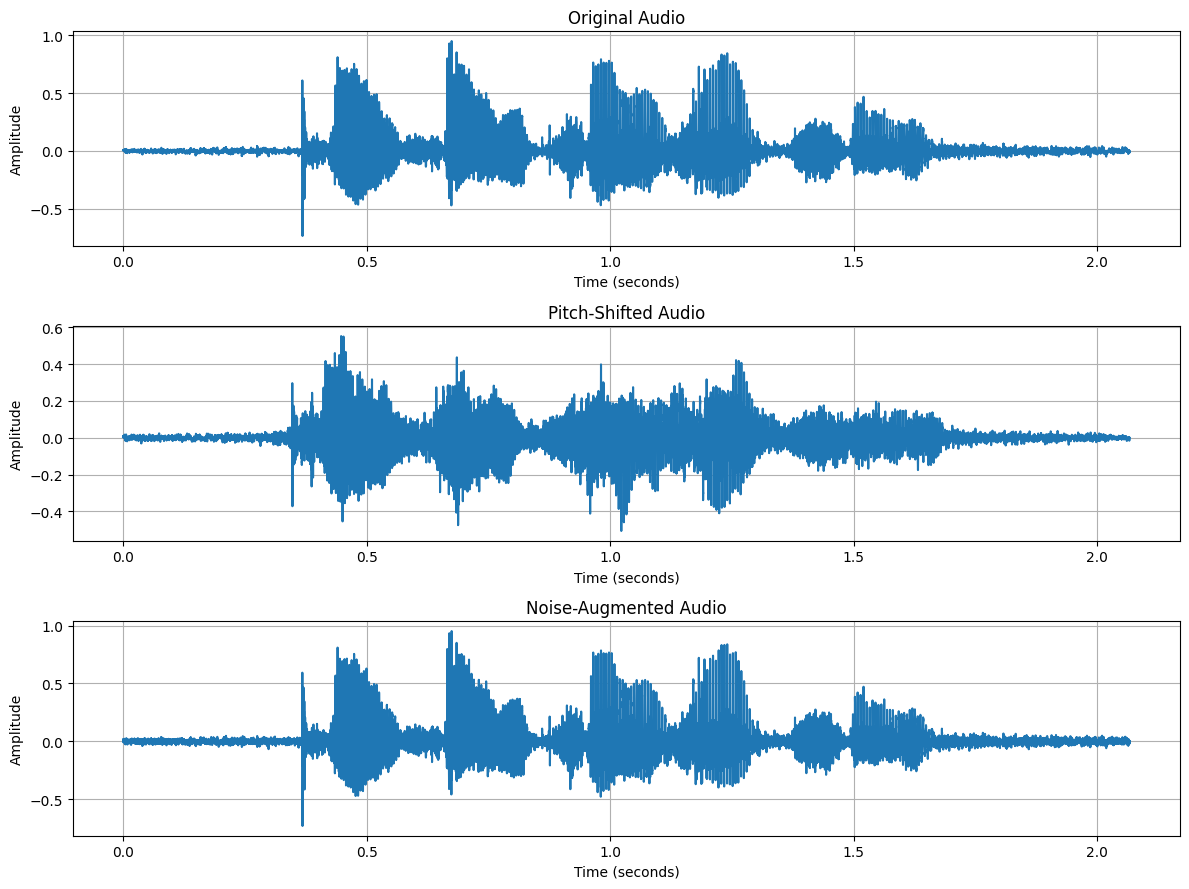

In [23]:

# Select the first original recording
original = processed_records[0]

# Find its two augmented versions
pitch_version = next(
    r for r in pitch_augmented_records
    if r["source_filename"] == original["filename"]
)

noise_version = next(
    r for r in noise_augmented_records
    if r["source_filename"] == original["filename"]
)

fig, axes = plt.subplots(3, 1, figsize=(12, 9))

examples = [
    (original["audio"], "Original Audio"),
    (pitch_version["audio"], "Pitch-Shifted Audio"),
    (noise_version["audio"], "Noise-Augmented Audio")
]

for ax, (audio, title) in zip(axes, examples):

    time = np.arange(len(audio)) / TARGET_SAMPLE_RATE

    ax.plot(time, audio)
    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


## 8. Audio Feature Extraction

Audio feature extraction converts speech recordings into numerical representations that can be used by machine learning models.

In this section, we extract the following audio features:

1. Mel-Frequency Cepstral Coefficients (MFCCs)
2. Spectral roll-off
3. Root Mean Square (RMS) energy
4. Spectral centroid
5. Zero-crossing rate

For each feature, we calculate the mean and standard deviation across the audio frames. This produces a fixed-length feature vector for each recording.

The extracted features will be used to support speaker verification and further analysis.


In [24]:

def extract_audio_features(audio, sample_rate):

    features = {}

    # 1. MFCC features (13 coefficients)
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sample_rate,
        n_mfcc=13
    )

    for i in range(13):
        features[f"mfcc_{i+1}_mean"] = np.mean(mfcc[i])
        features[f"mfcc_{i+1}_std"] = np.std(mfcc[i])

    # 2. Spectral roll-off
    rolloff = librosa.feature.spectral_rolloff(
        y=audio,
        sr=sample_rate
    )

    features["rolloff_mean"] = np.mean(rolloff)
    features["rolloff_std"] = np.std(rolloff)

    # 3. RMS energy
    rms = librosa.feature.rms(y=audio)

    features["rms_mean"] = np.mean(rms)
    features["rms_std"] = np.std(rms)

    # 4. Spectral centroid
    centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sample_rate
    )

    features["centroid_mean"] = np.mean(centroid)
    features["centroid_std"] = np.std(centroid)

    # 5. Zero-crossing rate
    zcr = librosa.feature.zero_crossing_rate(y=audio)

    features["zcr_mean"] = np.mean(zcr)
    features["zcr_std"] = np.std(zcr)

    return features


print("Audio feature extraction function defined successfully.")

Audio feature extraction function defined successfully.


In [25]:

feature_records = []

for record in all_audio_records:

    # Extract numerical features
    features = extract_audio_features(
        record["audio"],
        record["sample_rate"]
    )

    # Add recording information
    features["member_id"] = record["member_id"]
    features["filename"] = record["filename"]
    features["source_filename"] = record.get(
        "source_filename",
        record["filename"]
    )
    features["augmentation"] = record.get(
        "augmentation",
        "original"
    )

    feature_records.append(features)

# Create the feature dataframe
audio_features_df = pd.DataFrame(feature_records)

print("Feature extraction completed!")
print("Number of recordings:", len(audio_features_df))
print("Number of columns:", len(audio_features_df.columns))

display(audio_features_df.head())

Feature extraction completed!
Number of recordings: 18
Number of columns: 38


,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,mfcc_5_mean,mfcc_5_std,...,rms_mean,rms_std,centroid_mean,centroid_std,zcr_mean,zcr_std,member_id,filename,source_filename,augmentation
0,-166.270550,89.263765,103.810117,41.110518,11.434079,20.413197,-7.028166,23.905782,-15.228733,13.066353,...,0.101266,0.074551,1763.621183,792.954558,0.121161,0.076639,member_1,kellia_confirm_transaction.wav,kellia_confirm_transaction.wav,original
1,-188.373805,77.492162,105.619296,48.067596,28.711510,32.929691,3.929827,16.373823,-6.315942,11.733772,...,0.109040,0.106307,1795.689967,1124.434266,0.128044,0.140775,member_1,kellia_yes_approve.wav,kellia_yes_approve.wav,original
2,-219.310554,110.380955,103.255066,47.140147,-15.000499,29.793633,-19.347585,30.926635,-9.614138,18.305197,...,0.083882,0.070207,1740.232868,915.763450,0.146777,0.090086,member_2,Mildred_confirm_transaction.wav,Mildred_confirm_transaction.wav,original
3,-231.106922,112.165050,72.451137,66.000694,17.718239,42.747535,-5.364942,33.248280,-23.422405,23.480343,...,0.115058,0.108974,2402.345161,1408.303418,0.166027,0.136617,member_2,Mildred_yes_approve.wav,Mildred_yes_approve.wav,original
4,-215.418667,112.753512,94.502061,70.505674,16.694593,35.480476,49.655239,22.738596,16.568720,19.076847,...,0.165582,0.099189,1374.255157,1162.288142,0.111757,0.111427,member_3,Auriane_confirm_transaction.wav,Auriane_confirm_transaction.wav,original


In [26]:
# Select numerical feature columns
numeric_features = audio_features_df.select_dtypes(
    include=np.number
)

# Check missing values
missing_values = numeric_features.isnull().sum().sum()

# Check infinite values
infinite_values = np.isinf(numeric_features.to_numpy()).sum()

print("Feature dataset shape:", audio_features_df.shape)
print("Missing numerical values:", missing_values)
print("Infinite numerical values:", infinite_values)

if missing_values == 0 and infinite_values == 0:
    print("\nAll numerical features are valid!")
else:
    print("\nPlease investigate the missing or infinite values.")

Feature dataset shape: (18, 38)
Missing numerical values: 0
Infinite numerical values: 0

All numerical features are valid!


In [27]:
# Save extracted features
FEATURES_OUTPUT_PATH = (
    PROJECT_DIR / "data" / "processed" / "audio_features.csv"
)

FEATURES_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

audio_features_df.to_csv(
    FEATURES_OUTPUT_PATH,
    index=False
)

print("Audio features saved successfully!")
print("Location:", FEATURES_OUTPUT_PATH)

Audio features saved successfully!
Location: /content/drive/MyDrive/Formative-2-Multimodal-System/data/processed/audio_features.csv


## 9. Voiceprint Verification

Voiceprint verification is used to determine whether a voice recording
belongs to a claimed speaker.

In this project, we will use Mel-Frequency Cepstral Coefficients (MFCCs)
to represent important characteristics of each voice recording.

We will compare these feature representations using cosine similarity.

Only the six original recordings will be used to create the initial
speaker profiles. Augmented recordings will not be treated as independent
speaker recordings because they were generated from the original audio.

In [28]:
# Select only the original recordings
original_features = audio_features_df[
    audio_features_df["augmentation"] == "original"
].copy()

# Identify the MFCC feature columns
mfcc_feature_columns = [
    column for column in original_features.columns
    if column.startswith("mfcc_")
]

# Display the available original recordings
print("Original recordings:", len(original_features))
print("\nRecordings per team member:")
print(original_features.groupby("member_id").size())

print("\nNumber of MFCC features:", len(mfcc_feature_columns))
print("\nMFCC feature columns:")
print(mfcc_feature_columns)

Original recordings: 6

Recordings per team member:
member_id
member_1    2
member_2    2
member_3    2
dtype: int64

Number of MFCC features: 26

MFCC feature columns:
['mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'mfcc_13_mean', 'mfcc_13_std']


### 10. Building Speaker Voice Profiles

A voice profile is a numerical representation of a speaker's voice.

For each team member, we will:
1. Extract the 26 MFCC features from their original recordings.
2. Normalize each feature vector.
3. Calculate the average of the two recording vectors.
4. Normalize the average to create one representative voice profile.

These profiles will later be used to compare new recordings against
the enrolled speakers.

In [29]:
from sklearn.preprocessing import normalize

# Store one voice profile for each team member
voice_profiles = {}

for member_id, group in original_features.groupby("member_id"):

    # Extract the 26 MFCC features
    member_vectors = group[mfcc_feature_columns].to_numpy(dtype=float)

    # Normalize each recording's feature vector
    normalized_vectors = normalize(member_vectors)

    # Average the two recording vectors
    average_profile = normalized_vectors.mean(axis=0)

    # Normalize the final speaker profile
    speaker_profile = normalize(
        average_profile.reshape(1, -1)
    )[0]

    # Save the profile
    voice_profiles[member_id] = speaker_profile


# Display the generated profiles
print("VOICE PROFILES CREATED")
print("=" * 40)

for member_id, profile in voice_profiles.items():
    print(f"{member_id}: {profile.shape}")

print("\nTotal speaker profiles:", len(voice_profiles))

VOICE PROFILES CREATED
member_1: (26,)
member_2: (26,)
member_3: (26,)

Total speaker profiles: 3


### 11. Comparing Voice Profiles Using Cosine Similarity

Cosine similarity measures how similar two numerical feature vectors are.

It produces a score between -1 and 1:
- 1 means the vectors point in the same direction.
- 0 means they are unrelated in direction.
- -1 means they point in opposite directions.

We will compare each original recording against all three speaker profiles.

For evaluation, we will use a leave-one-recording-out approach:
one recording from each member is used for enrollment, while their other
recording is used as the verification sample.

This prevents a recording from being compared against a profile that
was built using that same recording.

In [30]:
from sklearn.metrics.pairwise import cosine_similarity

# Store verification results
verification_results = []

# Sort recordings consistently for each member
recordings_by_member = {
    member_id: group.sort_values("filename").reset_index(drop=True)
    for member_id, group in original_features.groupby("member_id")
}

# Perform two verification rounds
for fold in range(2):

    # Build temporary profiles using one recording per member
    temporary_profiles = {}

    for member_id, group in recordings_by_member.items():

        enrollment_row = group.iloc[fold]
        enrollment_vector = enrollment_row[mfcc_feature_columns].to_numpy(
            dtype=float
        ).reshape(1, -1)

        temporary_profiles[member_id] = normalize(enrollment_vector)[0]

    # Test the other recording from each member
    for member_id, group in recordings_by_member.items():

        query_row = group.iloc[1 - fold]
        query_vector = query_row[mfcc_feature_columns].to_numpy(
            dtype=float
        ).reshape(1, -1)

        query_vector = normalize(query_vector)

        # Compare against all three temporary profiles
        scores = {}

        for enrolled_member, profile in temporary_profiles.items():

            similarity = cosine_similarity(
                query_vector,
                profile.reshape(1, -1)
            )[0, 0]

            scores[enrolled_member] = float(similarity)

        # Identify the closest matching speaker
        predicted_member = max(scores, key=scores.get)

        verification_results.append({
            "query_member": member_id,
            "query_filename": query_row["filename"],
            "predicted_member": predicted_member,
            "genuine_similarity": scores[member_id],
            "highest_similarity": scores[predicted_member],
            "correct_match": predicted_member == member_id
        })

# Convert results into a DataFrame
verification_df = pd.DataFrame(verification_results)

# Display results
print("VOICE VERIFICATION RESULTS")
print("=" * 60)

display(verification_df)

print("\nCorrect speaker matches:",
      verification_df["correct_match"].sum(),
      "out of", len(verification_df))

VOICE VERIFICATION RESULTS


,query_member,query_filename,predicted_member,genuine_similarity,highest_similarity,correct_match
0,member_1,kellia_yes_approve.wav,member_1,0.987277,0.987277,True
1,member_2,Mildred_yes_approve.wav,member_2,0.979446,0.979446,True
2,member_3,Auriane_yes_approve.wav,member_3,0.973743,0.973743,True
3,member_1,kellia_confirm_transaction.wav,member_1,0.987277,0.987277,True
4,member_2,Mildred_confirm_transaction.wav,member_2,0.979446,0.979446,True
5,member_3,Auriane_confirm_transaction.wav,member_3,0.973743,0.973743,True



Correct speaker matches: 6 out of 6


### 12. Evaluating Voice Verification

To avoid testing recordings that were already used to build their
speaker profiles, we will use a leave-one-recording-out approach.

For each evaluation round:
1. One original recording from each member is used for enrollment.
2. The other original recording is used as the verification query.
3. Cosine similarity is calculated against all three enrolled profiles.
4. The predicted speaker is compared with the actual speaker.

We repeat the process with the recordings reversed.

This gives us six verification trials in total.

In [31]:
from sklearn.metrics.pairwise import cosine_similarity

loo_results = []

# Each member has two original recordings.
# We reverse which recording is used for enrollment in each round.
for query_index in range(2):

    enrollment_index = 1 - query_index

    # Build temporary profiles using only enrollment recordings
    temporary_profiles = {}

    for member_id, group in original_features.groupby("member_id"):

        group = group.sort_values("filename").reset_index(drop=True)

        enrollment_row = group.iloc[enrollment_index]

        enrollment_vector = enrollment_row[
            mfcc_feature_columns
        ].to_numpy(dtype=float).reshape(1, -1)

        temporary_profiles[member_id] = normalize(
            enrollment_vector
        )[0]

    # Verify the recordings that were not used for enrollment
    for member_id, group in original_features.groupby("member_id"):

        group = group.sort_values("filename").reset_index(drop=True)

        query_row = group.iloc[query_index]

        query_vector = query_row[
            mfcc_feature_columns
        ].to_numpy(dtype=float).reshape(1, -1)

        query_vector = normalize(query_vector)

        # Compare the query with every enrolled speaker
        similarity_scores = {
            enrolled_member: float(
                cosine_similarity(
                    query_vector,
                    profile.reshape(1, -1)
                )[0, 0]
            )
            for enrolled_member, profile in temporary_profiles.items()
        }

        predicted_member = max(
            similarity_scores,
            key=similarity_scores.get
        )

        genuine_similarity = similarity_scores[member_id]

        loo_results.append({
            "query_member": member_id,
            "query_filename": query_row["filename"],
            "predicted_member": predicted_member,
            "genuine_similarity": genuine_similarity,
            "highest_similarity": max(similarity_scores.values()),
            "correct_match": predicted_member == member_id
        })


# Display the evaluation results
loo_results_df = pd.DataFrame(loo_results)

print("LEAVE-ONE-RECORDING-OUT VERIFICATION RESULTS")
print("=" * 60)

display(loo_results_df.round(4))

correct_matches = loo_results_df["correct_match"].sum()
total_trials = len(loo_results_df)

print(f"\nCorrect speaker matches: {correct_matches} out of {total_trials}")
print(f"Verification accuracy: {correct_matches / total_trials:.2%}")

LEAVE-ONE-RECORDING-OUT VERIFICATION RESULTS


,query_member,query_filename,predicted_member,genuine_similarity,highest_similarity,correct_match
0,member_1,kellia_confirm_transaction.wav,member_1,0.9873,0.9873,True
1,member_2,Mildred_confirm_transaction.wav,member_2,0.9794,0.9794,True
2,member_3,Auriane_confirm_transaction.wav,member_3,0.9737,0.9737,True
3,member_1,kellia_yes_approve.wav,member_1,0.9873,0.9873,True
4,member_2,Mildred_yes_approve.wav,member_2,0.9794,0.9794,True
5,member_3,Auriane_yes_approve.wav,member_3,0.9737,0.9737,True



Correct speaker matches: 6 out of 6
Verification accuracy: 100.00%


### 13. Genuine and Impostor Similarity Analysis

A genuine comparison occurs when a recording is compared with the
profile of its actual speaker.

An impostor comparison occurs when a recording is compared with
another speaker's profile.

We will inspect both types of similarity scores to understand whether
the system can distinguish genuine speakers from other speakers.

In [32]:
# Recalculate genuine and impostor scores for each evaluation round
comparison_rows = []

for query_index in range(2):

    enrollment_index = 1 - query_index
    temporary_profiles = {}

    for member_id, group in original_features.groupby("member_id"):

        group = group.sort_values("filename").reset_index(drop=True)

        enrollment_vector = group.iloc[enrollment_index][
            mfcc_feature_columns
        ].to_numpy(dtype=float).reshape(1, -1)

        temporary_profiles[member_id] = normalize(enrollment_vector)[0]

    for actual_member, group in original_features.groupby("member_id"):

        group = group.sort_values("filename").reset_index(drop=True)

        query_row = group.iloc[query_index]

        query_vector = query_row[
            mfcc_feature_columns
        ].to_numpy(dtype=float).reshape(1, -1)

        query_vector = normalize(query_vector)

        for enrolled_member, profile in temporary_profiles.items():

            score = cosine_similarity(
                query_vector,
                profile.reshape(1, -1)
            )[0, 0]

            comparison_rows.append({
                "actual_member": actual_member,
                "compared_profile": enrolled_member,
                "comparison_type": (
                    "Genuine" if actual_member == enrolled_member
                    else "Impostor"
                ),
                "similarity": score
            })


comparison_df = pd.DataFrame(comparison_rows)

print("GENUINE VS IMPOSTOR COMPARISONS")
print("=" * 50)

display(
    comparison_df.round(4).sort_values(
        ["actual_member", "comparison_type", "compared_profile"]
    )
)

print("\nAverage genuine similarity:",
      round(comparison_df.loc[
          comparison_df["comparison_type"] == "Genuine",
          "similarity"
      ].mean(), 4))

print("Average impostor similarity:",
      round(comparison_df.loc[
          comparison_df["comparison_type"] == "Impostor",
          "similarity"
      ].mean(), 4))

GENUINE VS IMPOSTOR COMPARISONS


,actual_member,compared_profile,comparison_type,similarity
0,member_1,member_1,Genuine,0.9873
9,member_1,member_1,Genuine,0.9873
1,member_1,member_2,Impostor,0.9649
10,member_1,member_2,Impostor,0.9696
2,member_1,member_3,Impostor,0.9115
11,member_1,member_3,Impostor,0.9620
4,member_2,member_2,Genuine,0.9794
13,member_2,member_2,Genuine,0.9794
3,member_2,member_1,Impostor,0.9696
12,member_2,member_1,Impostor,0.9649



Average genuine similarity: 0.9802
Average impostor similarity: 0.9497


### 14. Selecting a Provisional Verification Threshold

A similarity threshold determines whether a voice recording is accepted
or rejected.

If the similarity is equal to or above the threshold, the speaker is
accepted. Otherwise, the recording is rejected.

For this educational prototype, we will calculate a provisional
threshold using the observed genuine and impostor similarity scores.

This threshold is specific to our small demonstration dataset and
must not be considered a reliable real-world authentication threshold.

In [33]:
# Separate genuine and impostor scores
genuine_scores = comparison_df.loc[
    comparison_df["comparison_type"] == "Genuine",
    "similarity"
]

impostor_scores = comparison_df.loc[
    comparison_df["comparison_type"] == "Impostor",
    "similarity"
]

# Calculate the provisional threshold
min_genuine = genuine_scores.min()
max_impostor = impostor_scores.max()

if max_impostor < min_genuine:
    VOICE_THRESHOLD = (max_impostor + min_genuine) / 2
else:
    VOICE_THRESHOLD = None

print("VOICE VERIFICATION THRESHOLD")
print("=" * 40)
print(f"Lowest genuine similarity: {min_genuine:.4f}")
print(f"Highest impostor similarity: {max_impostor:.4f}")

if VOICE_THRESHOLD is not None:
    print(f"Provisional threshold: {VOICE_THRESHOLD:.4f}")
else:
    print("No separating threshold found in the current results.")

VOICE VERIFICATION THRESHOLD
Lowest genuine similarity: 0.9737
Highest impostor similarity: 0.9696
Provisional threshold: 0.9717


In [34]:
if VOICE_THRESHOLD is not None:

    comparison_df["accepted"] = (
        comparison_df["similarity"] >= VOICE_THRESHOLD
    )

    genuine_acceptance = comparison_df.loc[
        comparison_df["comparison_type"] == "Genuine",
        "accepted"
    ].mean()

    impostor_rejection = 1 - comparison_df.loc[
        comparison_df["comparison_type"] == "Impostor",
        "accepted"
    ].mean()

    print("THRESHOLD EVALUATION")
    print("=" * 40)
    print(f"Genuine acceptance rate: {genuine_acceptance:.2%}")
    print(f"Impostor rejection rate: {impostor_rejection:.2%}")

THRESHOLD EVALUATION
Genuine acceptance rate: 100.00%
Impostor rejection rate: 100.00%


### 15. Creating the Reusable Voice Verification Module

We will create voice_model.py inside the src directory.

The module will provide a reusable VoiceVerifier class that can be
imported by the main application.

The main application will pass the claimed member ID, obtained from
the facial recognition component, together with the audio recording.

The voice verifier will check whether the recording matches the
claimed member's enrolled voice profile.

In [41]:
import os

# Ensure the target directory exists
os.makedirs("/content/drive/MyDrive/Formative-2-Multimodal-System/src", exist_ok=True)

code_content = """
import numpy as np
import pandas as pd
import librosa

from pathlib import Path
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity


TARGET_SAMPLE_RATE = 16000
DEFAULT_THRESHOLD = 0.97165

MFCC_COLUMNS = [
    f"mfcc_{i}_{stat}"
    for i in range(1, 14)
    for stat in ("mean", "std")
]


class VoiceVerifier:
    '''Verify a claimed speaker using enrolled MFCC voice profiles.

    Profiles can be loaded from a saved .npz archive. If no archive is
    supplied, they are built from original (non-augmented) rows in the
    feature CSV.
    '''

    def __init__(self, feature_csv_path=None, threshold=None, profiles_path=None):
        self.voice_profiles = {}

        if profiles_path is not None:
            self._load_profiles(profiles_path)
            saved_threshold = self.threshold
            self.threshold = (
                float(threshold) if threshold is not None else saved_threshold
            )
        else:
            if feature_csv_path is None:
                raise ValueError("Provide profiles_path or feature_csv_path.")
            self.threshold = (
                float(threshold) if threshold is not None else DEFAULT_THRESHOLD
            )
            self._build_profiles(feature_csv_path)

        if not 0 <= self.threshold <= 1:
            raise ValueError("threshold must be between 0 and 1.")

    def _build_profiles(self, feature_csv_path):
        features_df = pd.read_csv(feature_csv_path)
        required_metadata = {"augmentation", "member_id"}
        missing_metadata = required_metadata - set(features_df.columns)
        if missing_metadata:
            raise ValueError(
                f"Missing required metadata columns: {sorted(missing_metadata)}"
            )

        original_df = features_df[
            features_df["augmentation"] == "original"
        ].copy()
        if original_df.empty:
            raise ValueError("No original recordings found.")

        missing_columns = [
            col for col in MFCC_COLUMNS if col not in original_df.columns
        ]
        if missing_columns:
            raise ValueError(f"Missing MFCC columns: {missing_columns}")

        for member_id, group in original_df.groupby("member_id"):
            vectors = group[MFCC_COLUMNS].to_numpy(dtype=float)
            self._validate_feature_matrix(vectors)
            normalized_vectors = normalize(vectors)
            average_profile = normalized_vectors.mean(axis=0)
            profile = normalize(average_profile.reshape(1, -1))[0]
            self.voice_profiles[str(member_id)] = profile

        if not self.voice_profiles:
            raise ValueError("No enrolled speaker profiles could be built.")

    def _load_profiles(self, profiles_path):
        profiles_path = Path(profiles_path)
        if not profiles_path.is_file():
            raise FileNotFoundError(
                f"Saved voice profiles not found: {profiles_path}"
            )

        try:
            with np.load(profiles_path, allow_pickle=False) as archive:
                required_keys = {"member_ids", "profiles", "threshold"}
                missing_keys = required_keys - set(archive.files)
                if missing_keys:
                    raise ValueError(
                        f"Profile archive is missing keys: {sorted(missing_keys)}"
                    )
                member_ids = archive["member_ids"].astype(str)
                profiles = np.asarray(archive["profiles"], dtype=float)
                saved_threshold = float(archive["threshold"])
        except (OSError, KeyError) as exc:
            raise ValueError(f"Could not read saved voice profiles: {exc}") from exc

        if profiles.ndim != 2 or profiles.shape[1] != len(MFCC_COLUMNS):
            raise ValueError(
                f"Expected profile shape (number_of_speakers, {len(MFCC_COLUMNS)}), "
                f"got {profiles.shape}."
            )
        if len(member_ids) != profiles.shape[0]:
            raise ValueError(
                "The number of member IDs does not match the number of profiles."
            )
        if len(set(member_ids.tolist())) != len(member_ids):
            raise ValueError("Duplicate member IDs found in profile archive.")
        self._validate_feature_matrix(profiles)
        if not 0 <= saved_threshold <= 1:
            raise ValueError("Saved threshold must be between 0 and 1.")

        normalized_profiles = normalize(profiles)
        self.voice_profiles = {
            member_id: profile
            for member_id, profile in zip(member_ids, normalized_profiles)
        }
        self.threshold = saved_threshold

    @staticmethod
    def _validate_feature_matrix(values):
        if values.size == 0:
            raise ValueError("Feature data is empty.")
        if not np.isfinite(values).all():
            raise ValueError("Feature data contains NaN or infinite values.")
        if np.any(np.linalg.norm(values, axis=1) == 0):
            raise ValueError("Feature data contains an all-zero vector.")

    def extract_features(self, audio_path):
        audio, sample_rate = librosa.load(
            audio_path,
            sr=TARGET_SAMPLE_RATE,
            mono=True,
        )
        audio, _ = librosa.effects.trim(audio, top_db=30)
        if audio.size == 0:
            raise ValueError(f"No usable audio signal found in: {audio_path}")

        peak = np.max(np.abs(audio))
        if peak > 0:
            audio = audio / peak * 0.95

        mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=13)
        feature_values = []
        for coefficient in mfcc:
            feature_values.append(np.mean(coefficient))
            feature_values.append(np.std(coefficient))

        features = np.asarray(feature_values, dtype=float)
        self._validate_feature_matrix(features.reshape(1, -1))
        return features

    def verify(self, audio_path, claimed_member_id):
        claimed_member_id = str(claimed_member_id)
        if claimed_member_id not in self.voice_profiles:
            return {
                "verified": False,
                "claimed_member_id": claimed_member_id,
                "similarity": None,
                "threshold": self.threshold,
                "message": "Speaker is not enrolled.",
            }

        query_features = self.extract_features(audio_path)
        query_vector = normalize(query_features.reshape(1, -1))
        speaker_profile = self.voice_profiles[claimed_member_id].reshape(1, -1)
        similarity = float(
            cosine_similarity(query_vector, speaker_profile)[0, 0]
        )
        verified = similarity >= self.threshold

        return {
            "verified": verified,
            "claimed_member_id": claimed_member_id,
            "similarity": similarity,
            "threshold": self.threshold,
            "message": (
                "Voice verified." if verified else "Voice verification failed."
            ),
        }
"""

with open("/content/drive/MyDrive/Formative-2-Multimodal-System/src/voice_model.py", "w") as f:
    f.write(code_content.strip() + "\n")

print("voice_model.py written successfully!")

voice_model.py written successfully!


### 16. Testing the Voice Verification Module

We will import the VoiceVerifier class and test it using one of
the processed recordings.

This confirms that the module can load the enrolled profiles,
extract features from a WAV file, and return a verification result.

In [42]:
import sys
from pathlib import Path

# Define the correct source directory path
SRC_DIR = PROJECT_DIR / "src"

# Add the source directory to Python's import path
if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

from voice_model import VoiceVerifier

# Load the voice verifier
voice_verifier = VoiceVerifier(
    feature_csv_path=PROJECT_DIR / "data" / "processed" / "audio_features.csv",
    threshold=VOICE_THRESHOLD
)

# Test with Auriane's processed recording
test_audio_path = (
    PROCESSED_AUDIO_DIR
    / "member_3"
    / "Auriane_yes_approve.wav"
)

test_result = voice_verifier.verify(
    audio_path=test_audio_path,
    claimed_member_id="member_3"
)

print("VOICE MODEL TEST")
print("=" * 40)

for key, value in test_result.items():
    print(f"{key}: {value}")

VOICE MODEL TEST
verified: True
claimed_member_id: member_3
similarity: 0.9934139506642852
threshold: 0.9716543295284756
message: Voice verified.


In [43]:
# Use a valid test audio path from your processed recordings directory
test_file_path = PROCESSED_AUDIO_DIR / "member_3" / "Auriane_yes_approve.wav"

result = voice_verifier.verify(
    audio_path=str(test_file_path),
    claimed_member_id="member_3"
)

if result["verified"]:
    print("Voice accepted")
else:
    print("Access denied")

Voice accepted


### 17. Negative Authentication Tests

In this section, we test whether the voice verification system can reject unauthorised access attempts.

We perform three tests:

1. **Genuine speaker:** Auriane's recording claims to belong to Member 3. The system should accept the voice.
2. **Incorrect identity:** Auriane's recording claims to belong to Member 2. The system should reject the voice if the similarity score is below the verification threshold.
3. **Unknown identity:** Auriane's recording claims to belong to an unregistered member (Member 99). The system should reject the request because this identity has no enrolled voice profile.

These tests help us check both successful and unsuccessful authentication scenarios.

In [44]:
# Select Auriane's processed voice recording
auriane_audio = PROCESSED_AUDIO_DIR / "member_3" / "Auriane_yes_approve.wav"

# Test 1: Correct identity
genuine_test = voice_verifier.verify(
    audio_path=str(auriane_audio),
    claimed_member_id="member_3"
)

# Test 2: Incorrect identity
wrong_identity_test = voice_verifier.verify(
    audio_path=str(auriane_audio),
    claimed_member_id="member_2"
)

# Test 3: Unknown identity
unknown_identity_test = voice_verifier.verify(
    audio_path=str(auriane_audio),
    claimed_member_id="member_99"
)

# Display results
print("TEST 1: GENUINE SPEAKER")
print(genuine_test)

print("\nTEST 2: INCORRECT IDENTITY")
print(wrong_identity_test)

print("\nTEST 3: UNKNOWN IDENTITY")
print(unknown_identity_test)

TEST 1: GENUINE SPEAKER
{'verified': True, 'claimed_member_id': 'member_3', 'similarity': 0.9934139506642852, 'threshold': 0.9716543295284756, 'message': 'Voice verified.'}

TEST 2: INCORRECT IDENTITY
{'verified': False, 'claimed_member_id': 'member_2', 'similarity': 0.9492013798580008, 'threshold': 0.9716543295284756, 'message': 'Voice verification failed.'}

TEST 3: UNKNOWN IDENTITY
{'verified': False, 'claimed_member_id': 'member_99', 'similarity': None, 'threshold': 0.9716543295284756, 'message': 'Speaker is not enrolled.'}


### 18. Saving Voice Profiles

After creating the voice profiles, we save them as a NumPy archive (`.npz`) file.

This allows the system to reuse the enrolled speaker profiles and the selected verification threshold without rebuilding them every time.

The saved file contains:
- Member IDs
- Voice profile vectors
- Verification threshold

In [45]:
# Create the models directory
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Define the save location
profile_path = MODELS_DIR / "voice_profiles.npz"

# Save voice profiles and threshold
np.savez(
    profile_path,
    member_ids=np.array(list(voice_profiles.keys())),
    profiles=np.vstack(list(voice_profiles.values())),
    threshold=np.array(VOICE_THRESHOLD)
)

print("Voice profiles saved successfully!")
print("Location:", profile_path)
print("Number of enrolled members:", len(voice_profiles))

Voice profiles saved successfully!
Location: /content/drive/MyDrive/Formative-2-Multimodal-System/models/voice_profiles.npz
Number of enrolled members: 3


In [46]:
# Load the saved voice profiles
saved_data = np.load(profile_path)

loaded_member_ids = saved_data["member_ids"]
loaded_profiles = saved_data["profiles"]
loaded_threshold = saved_data["threshold"].item()

# Display verification
print("Loaded member IDs:", loaded_member_ids)
print("Profiles shape:", loaded_profiles.shape)
print("Loaded threshold:", loaded_threshold)

# Confirm successful loading
assert len(loaded_member_ids) == 3
assert loaded_profiles.shape == (3, 26)
assert np.isclose(loaded_threshold, VOICE_THRESHOLD)

print("\nAll saved voice profiles loaded successfully!")

Loaded member IDs: ['member_1' 'member_2' 'member_3']
Profiles shape: (3, 26)
Loaded threshold: 0.9716543295284756

All saved voice profiles loaded successfully!


### 19. Genuine vs. Impostor Similarity Visualisation

We compare voice similarity scores between:

- **Genuine comparisons:** Two recordings belonging to the same enrolled speaker.
- **Impostor comparisons:** Recordings belonging to different enrolled speakers.

Cosine similarity is used to measure how closely the MFCC feature vectors match. Higher scores indicate greater similarity.

This visualisation helps us understand how well the enrolled voice profiles distinguish between speakers. Due to the small dataset, the results are illustrative rather than a reliable real-world biometric evaluation.

Genuine comparisons: 3
Impostor comparisons: 12


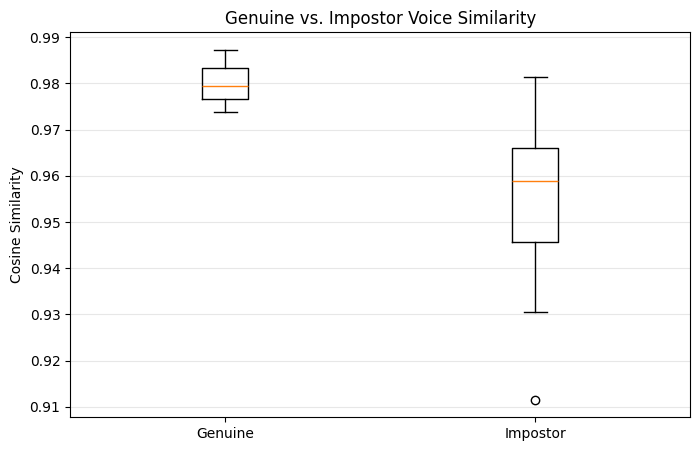

In [47]:
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Load the existing audio features
features_path = PROJECT_DIR / "data" / "processed" / "audio_features.csv"
audio_df = pd.read_csv(features_path)

# Select only original recordings
original_df = audio_df[audio_df["augmentation"] == "original"].copy()

# Select the 26 MFCC features
mfcc_columns = [
    f"mfcc_{i}_{stat}"
    for i in range(1, 14)
    for stat in ["mean", "std"]
]

# Calculate genuine and impostor similarities
genuine_scores = []
impostor_scores = []

for i in range(len(original_df)):
    for j in range(i + 1, len(original_df)):

        speaker_a = original_df.iloc[i]["member_id"]
        speaker_b = original_df.iloc[j]["member_id"]

        vector_a = original_df.iloc[i][mfcc_columns].values.astype(float).reshape(1, -1)
        vector_b = original_df.iloc[j][mfcc_columns].values.astype(float).reshape(1, -1)

        score = cosine_similarity(vector_a, vector_b)[0][0]

        if speaker_a == speaker_b:
            genuine_scores.append(score)
        else:
            impostor_scores.append(score)

print("Genuine comparisons:", len(genuine_scores))
print("Impostor comparisons:", len(impostor_scores))

# Plot the comparison
plt.figure(figsize=(8, 5))

plt.boxplot(
    [genuine_scores, impostor_scores],
    tick_labels=["Genuine", "Impostor"]
)

plt.ylabel("Cosine Similarity")
plt.title("Genuine vs. Impostor Voice Similarity")
plt.grid(axis="y", alpha=0.3)
plt.show()

##Interpretation
- **Genuine comparisons:** Similarity scores are concentrated around 0.98, showing strong similarity between recordings from the same speaker.
- **Impostor comparisons:** Scores are generally lower, with a median around 0.959, showing differences between speakers.
- **Some overlap:** The highest impostor scores approach the genuine scores, meaning different speakers can sometimes have similar voice characteristics.